# Høje Taastrup PTES data for 2024

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Functions for calculating density and specific heat of water as a function of temperature
def density_water(T):
    '''Calculates density (rho) of water in kg/m^3 based on fluid temperature (T) nearest the flow meter in degrees Celsius'''
    rho = (999.85+5.332*(10**-2)*T-7.564*(10**-3)*(T**2)+4.323*(10**-5)*(T**3)-1.673*(10**-7)*(T**4)+2.447*(10**-10)*(T**5))
    return(rho)

def specific_heat_water(T):
    '''Calculates specific heat (cp) of water in J/(kg K) based on mean fluid temperature (T) in degrees Celsius'''
    cp = (4.2184-2.8218*(10**-3)*T+7.3478*(10**-5)*(T**2)-9.4712*(10**-7)*(T**3)+7.2869*(10**-9)*(T**4)-2.8098*(10**-11)*(T**5)
          +4.4008*(10**-14)*(T**6))*1000
    return(cp)

### Read data

In [3]:
filename = 'ptes_operation_data_hoje_taastrup_2024.csv'
df = pd.read_csv(filename, index_col=[0], parse_dates=[0])

# plot the first 5 rows of the dataframe for inspection
df.head()

,A_00.25m,A_00.75m,A_01.25m,A_02.00m,A_03.00m,A_04.00m,A_05.00m,A_06.00m,A_06.50m,A_08.50m,...,F_bot,F_mid,T_bot_0.2m,T_bot_1.2m,T_bot_2.2m,T_amb,air_humidity,wind_speed,water_level_guided_radar,water_level_pressure
time,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00+00:00,86.08576,87.600525,87.382706,86.295890,78.828690,63.479390,53.837080,52.226826,52.290234,51.851604,...,0.0,0.0,50.101530,51.761170,50.640210,5.104376,100.0,3.780,36.672600,36.696890
2024-01-01 00:10:00+00:00,85.97182,87.596710,87.378520,86.293960,78.824486,63.478020,53.835167,52.227608,52.290550,51.851340,...,0.0,0.0,50.098667,51.760212,50.635445,5.116876,100.0,4.005,36.672497,36.696890
2024-01-01 00:20:00+00:00,85.86471,87.592896,87.374310,86.292060,78.820300,63.476494,53.833263,52.229134,52.290550,51.851727,...,0.0,0.0,50.095802,51.759260,50.630672,5.129376,100.0,2.710,36.672363,36.697410
2024-01-01 00:30:00+00:00,85.91485,87.589080,87.370120,86.290146,78.816090,63.474968,53.831352,52.230660,52.290550,51.852104,...,0.0,0.0,50.092945,51.758310,50.625908,5.141876,100.0,2.880,36.672234,36.697506
2024-01-01 00:40:00+00:00,86.02879,87.585266,87.365920,86.288246,78.811905,63.473442,53.829450,52.232185,52.290550,51.852490,...,0.0,0.0,50.090080,51.757355,50.621136,5.154376,100.0,2.790,36.672100,36.697456


In [4]:
# Make a list with all the temperature sensors in location A
A_strings = [c for c in df.columns if c.startswith('A')]
A_strings.sort()

# Make a list with all the temperature sensors in location B
B_strings = [c for c in df.columns if c.startswith('B')]
B_strings.sort()

# Group the ground temperature strings
ground_temp = [c for c in df.columns if c.startswith('T_ground')]

# Temperature sensors attached to the bottom of the storage
bottom_temp = ['T_bot_0.2m', 'T_bot_1.2m', 'T_bot_2.2m']

# make a list of all sensors measuring temperature in the storage
temperature_sensors = A_strings + B_strings + bottom_temp

In [5]:
# Ensure that all relative humidity measurements are always between 0-100 %
df.loc[(df['air_humidity']>100) | (df['air_humidity']<=0), 'air_humidity'] = np.nan
df.loc[(df['lid_humidity_1_1']>100) | (df['lid_humidity_1_1']<=0), 'lid_humidity_1_1'] = np.nan
df.loc[(df['lid_humidity_1_2']>100) | (df['lid_humidity_1_2']<=0), 'lid_humidity_1_2'] = np.nan
df.loc[(df['lid_humidity_2_1']>100) | (df['lid_humidity_2_1']<=0), 'lid_humidity_2_1'] = np.nan
df.loc[(df['lid_humidity_2_2']>100) | (df['lid_humidity_2_2']<=0), 'lid_humidity_2_2'] = np.nan

# Ensure that wind speed is never above 100 m/s
df.loc[df['wind_speed']>100, 'wind_speed'] = np.nan

# Ensure that all PTES water measurements are between 0 and 100 degC
for sensor in temperature_sensors:
    df.loc[(df[sensor]>100) | (df[sensor]<0), sensor] = np.nan

### Storage efficiency calculation

In [6]:
# The volumes were calculated from a 3D model of the PTES made in ANSYS Fluent.
# The volume of each layer was specified based on the distance between the temperature sensors.
# Each sensor is positioned at the middle of each layer.

volumes = [
    2018.9, 2638.2, 2577.4, 2517.1, 2457.3, 4157.8, 4533.7, 4305.1, 4080.9,
    3860.9, 3645.3, 3434.0, 3227.0, 3024.1, 2826.8, 4482.8, 4426.1, 2403.9,
    1727.6, 1559.4, 3191.1, 1452.0, 763.63, 453.5, 607.3, 259.4,
]

volume_per_layer = pd.Series(volumes)
volume_per_layer.sum()

70631.23

Fill in gaps by interpolation

In [7]:
df[A_strings] = df[A_strings].interpolate(axis=1, limit_direction='both')
df[A_strings] = df[A_strings].interpolate(axis=0, limit_direction='both')

# Check if there are any NaN values left in the dataset
print('Nan values = {}'.format(df[A_strings].isna().sum().sum()))

Nan values = 0


Calculate energy content

FileNotFoundError: [Errno 2] No such file or directory: '/home/tom/PycharmProjects/DynSys/results/plots/ptes_soc_hourly.png'

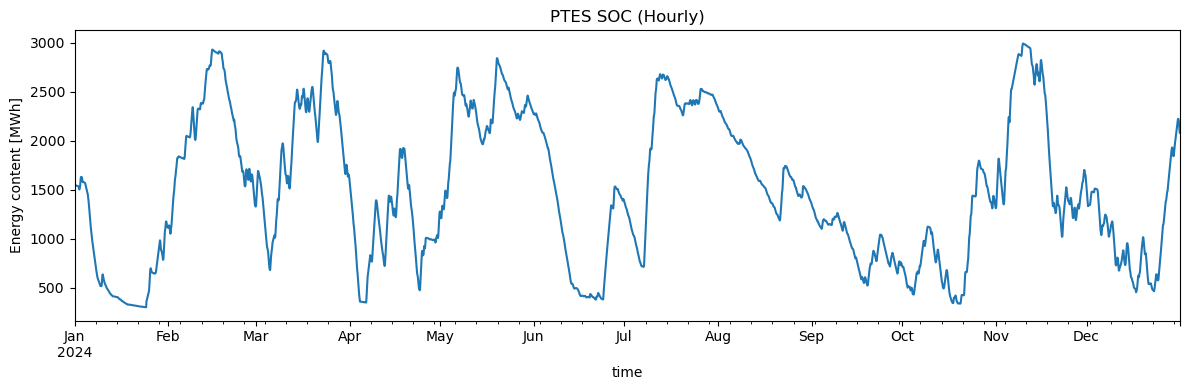

In [8]:
import matplotlib.pyplot as plt
plt.style.use("default")

T_ref = 48.5 # This value was used for the feasibility calculations (minimum temperature)
# Calculate the energy content per volume
heat_per_volume = df[A_strings].apply(density_water) * df[A_strings].apply(specific_heat_water) * (df[A_strings]-T_ref)

# Calculate the energy content per layer [MWh/layer]
heat_per_layer = heat_per_volume.multiply(list(volume_per_layer), axis='columns').divide(3600).divide(10**6)

# Sum them up for the total energy content of the storage
Q_storage = heat_per_layer.sum(axis='columns')

Q_hourly = Q_storage.resample("h").last()

plt.figure(figsize=(12,4))
Q_hourly.plot()
plt.ylabel("Energy content [MWh]")
plt.title("PTES SOC (Hourly)")
plt.tight_layout()

plot_path = "/home/tom/PycharmProjects/DynSys/results/plots/ptes_soc_hourly.png"
plt.savefig(plot_path, dpi=300)

plt.show()

# Change in SOC between hours
dQ = Q_hourly.diff().dropna()

# Charging energy (positive changes)
E_charge_total = dQ[dQ > 0].sum()

# Discharging energy (absolute value of negative changes)
E_discharge_total = -dQ[dQ < 0].sum()

print(f"Total charged energy: {E_charge_total:.1f} MWh")
print(f"Total discharged energy: {E_discharge_total:.1f} MWh")

E_capacity = 3300
cycles = E_discharge_total / E_capacity

print(f"Equivalent full cycles: {cycles:.2f} cycles/year")


# Combine into one export table
ptes_operation = pd.DataFrame(
    {
        "Q_storage_mwh": Q_hourly,
        "dQ_mwh": Q_hourly.diff(),
        "E_charge_mwh": Q_hourly.diff().clip(lower=0),
        "E_discharge_mwh": (-Q_hourly.diff()).clip(lower=0),
    }
)


# Export CSV
output_path = "ptes_operation_data_hourly.csv"
ptes_operation.to_csv(output_path, index_label="time")

print(f"Exported hourly PTES operation data to: {output_path}")
print(ptes_operation.head())

Calculate the monthly internal energy change

In [9]:
#eff_freq = '1ME'
eff_freq = '1D'
content_2023 = pd.Series(data=Q_storage.iloc[0], index=[pd.Timestamp('2023-12-31', tz='UTC')])
Q_internal_energy_change = pd.concat([Q_storage, content_2023]).resample(eff_freq).last().diff(1).iloc[1:]

Create a new monthly dataframe for finding the monthly energy efficiency

In [10]:
monthly = df[['E_discharge','E_charge']].resample(eff_freq).sum()
monthly['Delta_Q'] = Q_internal_energy_change

monthly['efficiency [%]'] = (monthly['E_discharge'] / (monthly['E_charge'] - monthly['Delta_Q']) *100).round(0)
monthly

,E_discharge,E_charge,Delta_Q,efficiency [%]
time,,,,
2024-01-01 00:00:00+00:00,0.000000,0.000000,-13.206873,0.0
2024-01-02 00:00:00+00:00,31.303737,124.381638,74.826433,63.0
2024-01-03 00:00:00+00:00,42.569543,16.374201,-35.727881,82.0
2024-01-04 00:00:00+00:00,66.163342,0.000000,-75.444758,88.0
2024-01-05 00:00:00+00:00,248.614796,0.000000,-256.176445,97.0
...,...,...,...,...
2024-12-27 00:00:00+00:00,0.000000,250.944043,235.867721,0.0
2024-12-28 00:00:00+00:00,0.000000,330.880781,314.745293,0.0
2024-12-29 00:00:00+00:00,85.883507,134.172693,27.962977,81.0


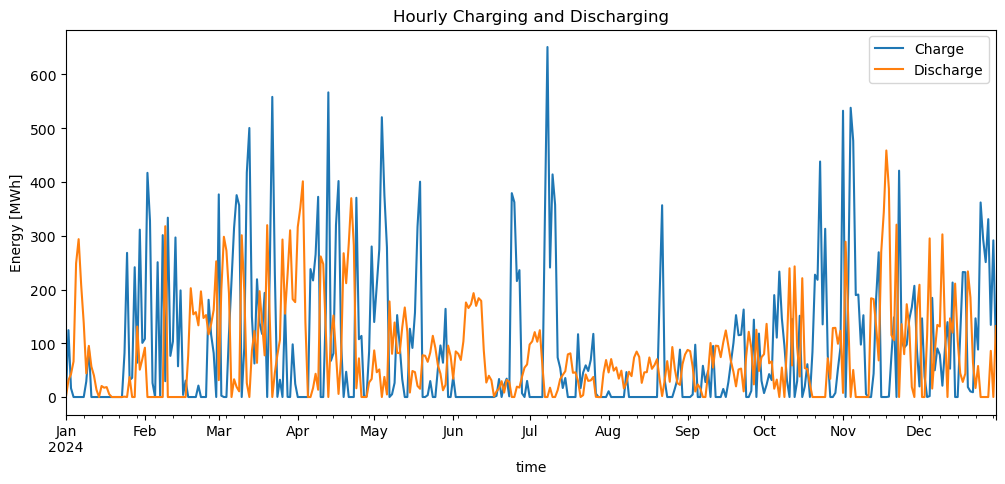

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12,5))

monthly['E_charge'].plot(ax=ax, label='Charge')
monthly['E_discharge'].plot(ax=ax, label='Discharge')

ax.set_ylabel("Energy [MWh]")
ax.set_title("Hourly Charging and Discharging")
ax.legend()

plt.show()

/tmp/ipykernel_31277/831796124.py:1: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly = df[['E_charge', 'E_discharge']].resample('1H').sum()


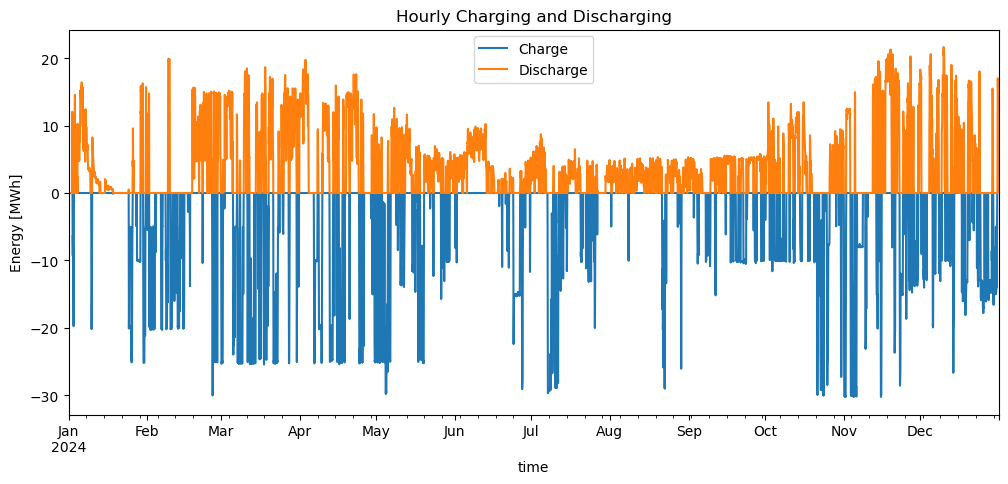

In [12]:
hourly = df[['E_charge', 'E_discharge']].resample('1H').sum()

fig, ax = plt.subplots(figsize=(12,5))

(-hourly['E_charge']).plot(ax=ax, label='Charge')
hourly['E_discharge'].plot(ax=ax, label='Discharge')

ax.set_ylabel("Energy [MWh]")
ax.set_title("Hourly Charging and Discharging")
ax.legend()

plt.show()

In [13]:
eff = (monthly['E_discharge'].sum() / (monthly['E_charge'].sum() - monthly['Delta_Q'].sum()) *100).round(0)
print(f'The yearly efficiency for 2024 is: {eff} %')

The yearly efficiency for 2024 is: 89.0 %


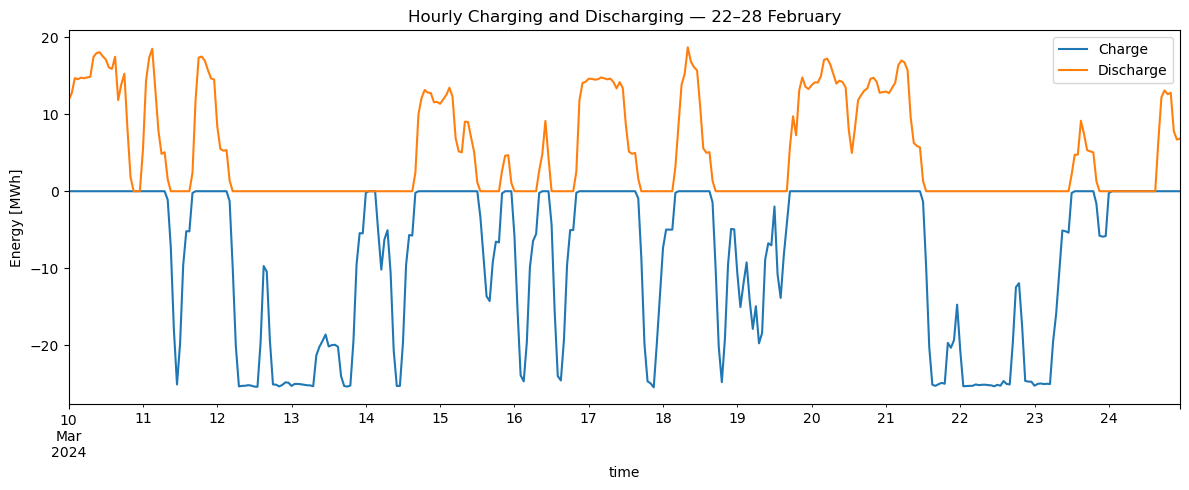

In [19]:
hourly = df[['E_charge', 'E_discharge']].resample('1h').sum()
week = hourly.loc['2024-03-10':'2024-03-24']

fig, ax = plt.subplots(figsize=(12, 5))

(-week['E_charge']).plot(ax=ax, label='Charge')
week['E_discharge'].plot(ax=ax, label='Discharge')

ax.set_ylabel("Energy [MWh]")
ax.set_title("Hourly Charging and Discharging — 22–28 February")
ax.legend()

plt.tight_layout()
plt.show()